In [1]:
import numpy as np
import pandas as pd
import os

from astropy.coordinates import SkyCoord, search_around_sky
import astropy.units as u
from astropy.io import fits
from astropy.table import Table

import matplotlib.pyplot as plt
from astropy.visualization import make_lupton_rgb
plt.style.use("dark_background")

In [2]:
pathdata = '/Users/jimenagonzalez/research/DSPL/Hybrid_SL_Modeling/data/candidates_data/'
filename_data = 'mycand' #SLED
path_stars = '/Users/jimenagonzalez/research/DSPL/Hybrid_SL_Modeling/Traditional_Modeling/psf_stuff/stars_data/'
filename_stars = 'forcross-mycand.csv' #SLED

data = pd.read_csv(pathdata + filename_data + '_old.csv')
threshold = 1.25 #1.25, 1.2   SLED
print('Original length: ', len(data))
data = data[data['EXP_SCORE'] >= threshold]
data_stars = pd.read_csv(path_stars + filename_stars )

#Candidate images from fits file, making sure images and data correspond to the same objects
hdu_list = fits.open(pathdata + filename_data + '.fits')
images = hdu_list[1].data
data_fits = Table(hdu_list[2].data).to_pandas() #data_fits has a different order than data
pos = pd.Series(np.arange(len(data_fits)), index=data_fits['COADD_OBJECT_ID'])
order = pos.loc[data['COADD_OBJECT_ID']].values# positions in data_fits, in the order that data has
data_fits = data_fits.iloc[order].reset_index(drop=True)

images = hdu_list[1].data[order]
data = data.reset_index(drop=True)

print(len(data), len(data_stars))

Original length:  2502
653 315346


In [3]:
data.head()

,COADD_OBJECT_ID,TILENAME,RA,DEC,EXP_SCORE,FLUX_RADIUS_G,FLUX_RADIUS_R,FLUX_RADIUS_I,KRON_RADIUS,MAG_AUTO_G,MAG_AUTO_R,MAG_AUTO_I,MOF_BDF_G_1,MOF_BDF_G_2,MOF_BDF_T,EXT_COADD,MAG_APER_4_G,MAG_APER_4_R,MAG_APER_4_I
0,873977986,DES2013-5248,303.116261,-52.618106,1.773398,4.834239,3.868224,3.986479,3.500000,24.681046,22.672300,21.386593,0.173669,-0.038793,1.976811,3,25.862455,23.496166,22.236557
1,873987650,DES2012-5748,303.580770,-57.950454,1.954167,8.545885,6.148588,4.866073,3.879309,22.223629,20.915426,19.904045,0.088356,-0.151831,5.384591,3,24.386759,22.202927,20.948452
2,885335814,DES2055-4249,314.065935,-42.649263,2.136731,6.022517,5.782853,4.968587,3.951247,21.662664,20.926882,20.430857,-0.052762,-0.084120,3.010771,3,23.461906,22.471380,21.607033
3,885361752,DES2055-4249,313.996641,-42.901952,1.792988,9.334122,8.720154,7.385244,4.400333,22.487700,21.316782,20.474627,-0.004590,0.000722,13.544633,3,25.349403,23.250080,21.937597
4,895521971,DES2039-5457,309.199035,-54.661722,1.266670,4.299431,3.775389,3.612022,3.500000,21.779581,20.797064,20.316587,0.005672,-0.112996,1.170487,3,22.779308,21.575483,21.034163


In [4]:
data_fits.head()

,COADD_OBJECT_ID,TILENAME,RA,DEC,Exp_score
0,873977986,DES2013-5248,303.116261,-52.618106,1.773398
1,873987650,DES2012-5748,303.580770,-57.950454,1.954167
2,885335814,DES2055-4249,314.065935,-42.649263,2.136731
3,885361752,DES2055-4249,313.996641,-42.901952,1.792988
4,895521971,DES2039-5457,309.199035,-54.661722,1.266670


In [5]:
data_stars.head()

,coadd_object_id,ra,dec,tilename,hpix_4096
0,1356611525,45.033761,1.072895,DES0259+0043,3951
1,1356612860,45.050531,1.070890,DES0259+0043,3951
2,1356614766,44.977122,1.045478,DES0259+0043,3991
3,1356613515,44.969229,1.066421,DES0259+0043,3997
4,1356613717,44.974724,1.065433,DES0259+0043,3997


In [6]:
cand_coords = SkyCoord(ra=data['RA'].values * u.deg, dec=data['DEC'].values * u.deg)
star_coords = SkyCoord(ra=data_stars['ra'].values * u.deg, dec=data_stars['dec'].values * u.deg)

search_radius = 3 * u.arcmin  # starting point -- tune based on results below

idx_cand, idx_star, sep2d, _ = search_around_sky(cand_coords, star_coords, search_radius)

matches = pd.DataFrame({'cand_idx': idx_cand, 'star_idx': idx_star, 'sep_arcsec': sep2d.arcsec,})

In [7]:
n_stars_wanted = 5

matches_sorted = matches.sort_values(['cand_idx', 'sep_arcsec'])
top_matches = matches_sorted.groupby('cand_idx').head(n_stars_wanted)

# attach candidate and star info for convenience
top_matches = top_matches.merge(data.reset_index().rename(columns={'index': 'cand_idx'}), on='cand_idx', suffixes=('', '_cand'))
top_matches = top_matches.merge(data_stars.reset_index().rename(columns={'index': 'star_idx'}), on='star_idx', suffixes=('', '_star') )

print(len(top_matches))
top_matches.head()

3155


,cand_idx,star_idx,sep_arcsec,COADD_OBJECT_ID,TILENAME,RA,DEC,EXP_SCORE,FLUX_RADIUS_G,FLUX_RADIUS_R,...,MOF_BDF_T,EXT_COADD,MAG_APER_4_G,MAG_APER_4_R,MAG_APER_4_I,coadd_object_id,ra,dec,tilename,hpix_4096
0,0,260171,20.530133,873977986,DES2013-5248,303.116261,-52.618106,1.773398,4.834239,3.868224,...,1.976811,3,25.862455,23.496166,22.236557,873978189,303.125343,-52.619562,DES2013-5248,188410367
1,0,260237,21.275160,873977986,DES2013-5248,303.116261,-52.618106,1.773398,4.834239,3.868224,...,1.976811,3,25.862455,23.496166,22.236557,873977294,303.117300,-52.612230,DES2013-5248,188410709
2,0,260170,28.342139,873977986,DES2013-5248,303.116261,-52.618106,1.773398,4.834239,3.868224,...,1.976811,3,25.862455,23.496166,22.236557,873978739,303.124179,-52.624341,DES2013-5248,188410367
3,0,260236,37.988404,873977986,DES2013-5248,303.116261,-52.618106,1.773398,4.834239,3.868224,...,1.976811,3,25.862455,23.496166,22.236557,873976898,303.114840,-52.607589,DES2013-5248,188410709
4,0,260233,38.457133,873977986,DES2013-5248,303.116261,-52.618106,1.773398,4.834239,3.868224,...,1.976811,3,25.862455,23.496166,22.236557,873978571,303.100290,-52.622590,DES2013-5248,188410708


In [8]:
counts = matches.groupby('cand_idx').size()
n_candidates = len(data)

print(f"{len(counts)} / {n_candidates} candidates have at least 1 star")
print(f"{(counts >= 3).sum()} candidates have >= 3 stars")
print(f"{(counts >= n_stars_wanted).sum()} candidates have >= {n_stars_wanted} stars")

# candidates with zero matches at all:
no_match_idx = set(range(n_candidates)) - set(counts.index)
print(f"{len(no_match_idx)} candidates have NO stars within {search_radius}")

631 / 653 candidates have at least 1 star
631 candidates have >= 3 stars
631 candidates have >= 5 stars
22 candidates have NO stars within 3.0 arcmin


22
3155


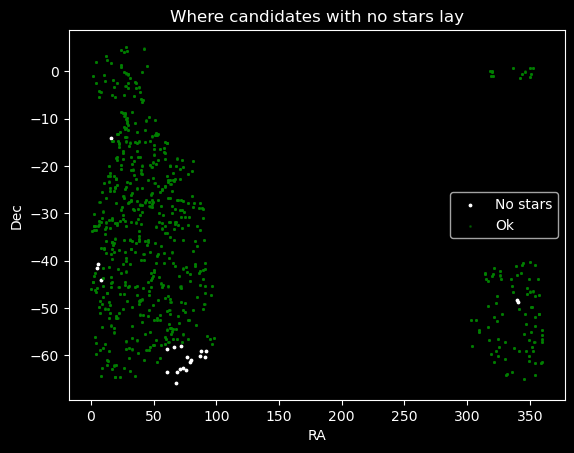

In [9]:
no_match_idx = sorted(set(range(len(data))) - set(counts.index))

no_match = data.iloc[no_match_idx]#[['COADD_OBJECT_ID', 'TILENAME', 'RA', 'DEC', 'EXP_SCORE']] #Candidates with no stars
print(len(no_match))

data_tmp1 = data_stars.iloc[top_matches['star_idx']] #stars that were cross-match
print(len(data_tmp1))

plt.figure()
plt.title('Where candidates with no stars lay')
plt.xlabel('RA')
plt.ylabel('Dec')
plt.scatter(no_match['RA'], no_match['DEC'], s=3, label='No stars', color='white')
plt.scatter(data_tmp1['ra'], data_tmp1['dec'], s=1, label='Ok', color='green', alpha=0.5)
plt.legend()
plt.show()

In [10]:
def make_plot_all(images, column_data, Q=9, stretch=40, minimum=(0,0,0)):
    for i in range(len(images)):
        if(i%12 == 0):
            plt.figure(figsize=(14,2))
            for j in range(12):
                if(i+j > len(images)-1): break
                plt.subplot(1,12,j+1)
                title = '{:.2f}'.format(column_data.iloc[i+j])
                plt.title(title)
                rgb = make_lupton_rgb(images[i+j][2], images[i+j][1], images[i+j][0], 
                                    Q=Q, stretch=stretch, minimum=minimum)
                plt.imshow(rgb, aspect='equal')
                plt.xticks([], [])
                plt.yticks([], []) 
            plt.show() 
    plt.close() 

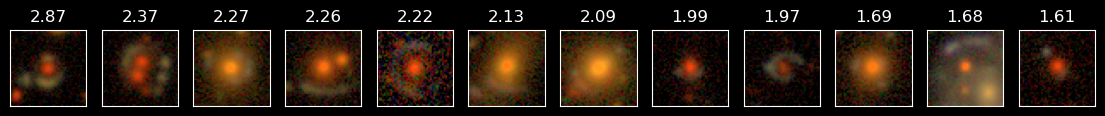

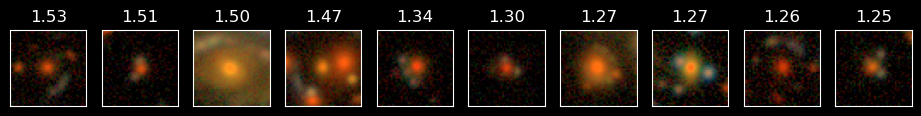

In [11]:
# Candidates with no high-quality, nearby stars
data_tmp = no_match.sort_values(['EXP_SCORE'], ascending=False)
images_tmp = images[data_tmp.index]
make_plot_all(images_tmp, data_tmp['EXP_SCORE'])

In [12]:
top_matches.head()
top_matches.columns

column_names = ['coadd_object_id', 'ra', 'dec', 'tilename', 'hpix_4096']
top_matches.rename(columns={c: c + '_star' for c in column_names}, inplace=True)

In [13]:
top_matches

,cand_idx,star_idx,sep_arcsec,COADD_OBJECT_ID,TILENAME,RA,DEC,EXP_SCORE,FLUX_RADIUS_G,FLUX_RADIUS_R,...,MOF_BDF_T,EXT_COADD,MAG_APER_4_G,MAG_APER_4_R,MAG_APER_4_I,coadd_object_id_star,ra_star,dec_star,tilename_star,hpix_4096_star
0,0,260171,20.530133,873977986,DES2013-5248,303.116261,-52.618106,1.773398,4.834239,3.868224,...,1.976811,3,25.862455,23.496166,22.236557,873978189,303.125343,-52.619562,DES2013-5248,188410367
1,0,260237,21.275160,873977986,DES2013-5248,303.116261,-52.618106,1.773398,4.834239,3.868224,...,1.976811,3,25.862455,23.496166,22.236557,873977294,303.117300,-52.612230,DES2013-5248,188410709
2,0,260170,28.342139,873977986,DES2013-5248,303.116261,-52.618106,1.773398,4.834239,3.868224,...,1.976811,3,25.862455,23.496166,22.236557,873978739,303.124179,-52.624341,DES2013-5248,188410367
3,0,260236,37.988404,873977986,DES2013-5248,303.116261,-52.618106,1.773398,4.834239,3.868224,...,1.976811,3,25.862455,23.496166,22.236557,873976898,303.114840,-52.607589,DES2013-5248,188410709
4,0,260233,38.457133,873977986,DES2013-5248,303.116261,-52.618106,1.773398,4.834239,3.868224,...,1.976811,3,25.862455,23.496166,22.236557,873978571,303.100290,-52.622590,DES2013-5248,188410708
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3150,652,75214,29.594034,1621679742,DES0143-6248,26.521536,-62.621424,2.054303,6.546799,5.172918,...,3.215055,3,24.297846,22.770126,21.544756,1621679420,26.508528,-62.615786,DES0143-6248,137151951
3151,652,75213,37.493252,1621679742,DES0143-6248,26.521536,-62.621424,2.054303,6.546799,5.172918,...,3.215055,3,24.297846,22.770126,21.544756,1621680535,26.500729,-62.625538,DES0143-6248,137151951
3152,652,75228,43.878901,1621679742,DES0143-6248,26.521536,-62.621424,2.054303,6.546799,5.172918,...,3.215055,3,24.297846,22.770126,21.544756,1621679528,26.546644,-62.617522,DES0143-6248,137151960
3153,652,75219,45.088123,1621679742,DES0143-6248,26.521536,-62.621424,2.054303,6.546799,5.172918,...,3.215055,3,24.297846,22.770126,21.544756,1621680408,26.545155,-62.627662,DES0143-6248,137151954


In [14]:
#Save top_match and a file to get the stars cutouts
top_matches.to_csv(path_stars + 'allcross_' + filename_data + '.csv', index=False) #To not cross-matching again the star cutouts

column_names = ['coadd_object_id_star', 'ra_star', 'dec_star']
data_tmp = top_matches[column_names]

data_tmp.rename(columns={c: c[:-5] for c in column_names}, inplace=True)

data_tmp.to_csv(path_stars + 'forcutouts_' + filename_data + '.csv', index=False) #To request the star cutouts